# Tutorial PM4Py sul BPI Challenge 2012

## Dall'esplorazione dell'event log al DFG, Alpha Miner e Inductive Miner

Questo notebook è una guida pratica, passo per passo, al **BPI Challenge 2012 (BPIC12)**. Il log descrive la gestione di richieste di prestito personale o scoperto bancario presso un istituto finanziario olandese.

L'obiettivo è imparare a:

1. scaricare e importare il file XES originale;
2. distinguere attività, lifecycle transition e attributi di caso;
3. esplorare qualità, distribuzione, varianti, risorse e tempi;
4. separare i tre sottoprocessi `A_`, `O_` e `W_`;
5. costruire Frequency DFG e Performance DFG;

> **Nota sul dataset:** il log BPIC12 completo è comunemente descritto con circa 13.087 casi, 262.200 eventi e 36 attività. Le varianti del dataset e le trasformazioni applicate possono produrre conteggi differenti. Nel notebook i valori effettivi vengono sempre calcolati dal file caricato: i numeri di letteratura sono riferimenti orientativi, non assert obbligatori.

### Una particolarità fondamentale di BPIC12

Le attività appartengono a tre sottoprocessi intrecciati:

- `A_`: Application — stati della domanda;
- `O_`: Offer — stati dell'offerta;
- `W_`: Work item — lavoro operativo degli operatori.

Le attività `A_` e `O_` sono normalmente registrate con lifecycle `COMPLETE`; le attività `W_` possono avere `SCHEDULE`, `START` e `COMPLETE`. Per questo motivo analizzeremo **sia il log grezzo sia un log filtrato sui soli eventi `COMPLETE`**. Quest'ultimo è generalmente una base più leggibile per il process discovery tradizionale, mentre il log grezzo conserva informazioni temporali utili sulle attività di lavoro.

## 0. Mappa del percorso

| Fase | Cosa facciamo |
|---|---|
| 1 | Installazione e import |
| 2 | Download / caricamento XES |
| 3 | Comprensione delle colonne e lifecycle |
| 4 | Data quality |
| 5 | Statistiche, attività e risorse |
| 6 | Varianti, start/end e frequenze |
| 7 | Sottoprocessi A, O e W |
| 8 | Filtri e sotto-log |
| 9 | DFG e Performance DFG |

## 1. Installazione delle librerie

In [1]:
pip install -U  pm4py pandas numpy matplotlib seaborn requests graphviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 2.4 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 17.2 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 23.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 24.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 21.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 24.6 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 5.3 MB/s  0:00:01m0:00:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 24.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 21.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 28.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23/23 [pm4py]m22/23 [pm4py]n]ib]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install

PM4Py richiede anche Graphviz per alcune visualizzazioni dei modelli.

- **Windows:** installa Graphviz dal sito ufficiale e verifica che `dot` sia nel `PATH`.
- **macOS:** `brew install graphviz`.
- **Ubuntu/Debian:** `sudo apt-get install graphviz`.

Se usi Google Colab, puoi provare:

## 2. Import delle librerie e configurazione

In [92]:
from pathlib import Path
import gzip
import shutil
import warnings
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pm4py

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)

sns.set_theme()

print("PM4Py:", pm4py.__version__)
print("Pandas:", pd.__version__)

PM4Py: 2.7.23.11
Pandas: 3.1.0


## 3. Scaricare il dataset BPI Challenge 2012

La fonte istituzionale del dataset è il portale **4TU.ResearchData / Eindhoven University of Technology**:

- DOI: <https://doi.org/10.4121/uuid:3926db30-f712-4394-aebc-75976070e91f>


## 4. Importare il file XES con PM4Py

In [93]:

XES_PATH = "/Users/vincenzo/Documents/lezioni/DMII/process_mining/event_log/BPI_Challenge_2012.xes.gz"
log_raw = pm4py.read_xes(str(XES_PATH))

print("Tipo:", type(log_raw))
print("Shape:", log_raw.shape)
display(log_raw.head())

parsing log, completed traces :: 100%|██████████| 13087/13087 [00:11<00:00, 1149.48it/s]


Tipo: <class 'pandas.DataFrame'>
Shape: (262200, 7)


,org:resource,lifecycle:transition,concept:name,time:timestamp,case:REG_DATE,case:concept:name,case:AMOUNT_REQ
0,112,COMPLETE,A_SUBMITTED,2011-09-30 22:38:44.546+00:00,2011-09-30 22:38:44.546+00:00,173688,20000
1,112,COMPLETE,A_PARTLYSUBMITTED,2011-09-30 22:38:44.880+00:00,2011-09-30 22:38:44.546+00:00,173688,20000
2,112,COMPLETE,A_PREACCEPTED,2011-09-30 22:39:37.906+00:00,2011-09-30 22:38:44.546+00:00,173688,20000
3,112,SCHEDULE,W_Completeren aanvraag,2011-09-30 22:39:38.875+00:00,2011-09-30 22:38:44.546+00:00,173688,20000
4,NaN,START,W_Completeren aanvraag,2011-10-01 09:36:46.437+00:00,2011-09-30 22:38:44.546+00:00,173688,20000


## 5. Comprendere la struttura del log

Le colonne XES più importanti sono:

| Colonna | Significato |
|---|---|
| `case:concept:name` | Identificativo del caso |
| `concept:name` | Nome dell'attività / stato |
| `time:timestamp` | Timestamp dell'evento |
| `lifecycle:transition` | Fase del lifecycle (`schedule`, `start`, `complete`) |
| `org:resource` | Risorsa / operatore, quando disponibile |
| `case:...` | Attributi associati al caso, ad esempio importo richiesto |

Non assumere che ogni versione del file abbia esattamente le stesse colonne: prima esplorale.

In [95]:
print("Numero colonne:", len(log_raw.columns))
print("Colonne disponibili:")
for col in log_raw.columns:
    print(" -", col)

print("\nTipi di dato:")
display(log_raw.dtypes.rename("dtype").to_frame())

Numero colonne: 7
Colonne disponibili:
 - org:resource
 - lifecycle:transition
 - concept:name
 - time:timestamp
 - case:REG_DATE
 - case:concept:name
 - case:AMOUNT_REQ

Tipi di dato:


,dtype
org:resource,str
lifecycle:transition,str
concept:name,str
time:timestamp,"datetime64[us, UTC]"
case:REG_DATE,"datetime64[us, UTC]"
case:concept:name,str
case:AMOUNT_REQ,str


### 5.1 Verificare le colonne fondamentali

In [96]:
CASE_COL = "case:concept:name"
ACTIVITY_COL = "concept:name"
TIMESTAMP_COL = "time:timestamp"
LIFECYCLE_COL = "lifecycle:transition"
RESOURCE_COL = "org:resource"

required = [CASE_COL, ACTIVITY_COL, TIMESTAMP_COL]
missing_required = [c for c in required if c not in log_raw.columns]

if missing_required:
    raise KeyError(
        f"Nel file mancano colonne fondamentali: {missing_required}. "
        f"Colonne trovate: {log_raw.columns.tolist()}"
    )

print("Colonne fondamentali presenti.")
print("Lifecycle disponibile:", LIFECYCLE_COL in log_raw.columns)
print("Risorsa disponibile:", RESOURCE_COL in log_raw.columns)

Colonne fondamentali presenti.
Lifecycle disponibile: True
Risorsa disponibile: True


### 5.2 Normalizzazione minima senza perdere il log originale

In [97]:
# Conserviamo log_raw come copia grezza importata e lavoriamo su log.
log = log_raw.copy()

log[CASE_COL] = log[CASE_COL].astype("string")
log[ACTIVITY_COL] = log[ACTIVITY_COL].astype("string").str.strip()
log[TIMESTAMP_COL] = pd.to_datetime(log[TIMESTAMP_COL], errors="coerce", utc=True)

if LIFECYCLE_COL in log.columns:
    log["lifecycle_norm"] = (
        log[LIFECYCLE_COL].astype("string").str.strip().str.lower()
    )
else:
    log["lifecycle_norm"] = pd.NA

log = log.sort_values([CASE_COL, TIMESTAMP_COL], kind="stable").reset_index(drop=True)

display(log.head())

,org:resource,lifecycle:transition,concept:name,time:timestamp,case:REG_DATE,case:concept:name,case:AMOUNT_REQ,lifecycle_norm
0,112,COMPLETE,A_SUBMITTED,2011-09-30 22:38:44.546+00:00,2011-09-30 22:38:44.546+00:00,173688,20000,complete
1,112,COMPLETE,A_PARTLYSUBMITTED,2011-09-30 22:38:44.880+00:00,2011-09-30 22:38:44.546+00:00,173688,20000,complete
2,112,COMPLETE,A_PREACCEPTED,2011-09-30 22:39:37.906+00:00,2011-09-30 22:38:44.546+00:00,173688,20000,complete
3,112,SCHEDULE,W_Completeren aanvraag,2011-09-30 22:39:38.875+00:00,2011-09-30 22:38:44.546+00:00,173688,20000,schedule
4,NaN,START,W_Completeren aanvraag,2011-10-01 09:36:46.437+00:00,2011-09-30 22:38:44.546+00:00,173688,20000,start


## 6. Dimensione del log e statistiche di base

In [98]:
summary = pd.Series({
    "eventi": len(log),
    "casi": log[CASE_COL].nunique(dropna=True),
    "attività distinte": log[ACTIVITY_COL].nunique(dropna=True),
    "risorse distinte": log[RESOURCE_COL].nunique(dropna=True) if RESOURCE_COL in log else np.nan,
    "varianti distinte (sequenza grezza)": log.groupby(CASE_COL)[ACTIVITY_COL].agg(tuple).nunique()
})

display(summary.to_frame("valore"))

print("Primo timestamp:", log[TIMESTAMP_COL].min())
print("Ultimo timestamp:", log[TIMESTAMP_COL].max())

,valore
eventi,262200
casi,13087
attività distinte,24
risorse distinte,68
varianti distinte (sequenza grezza),4366


Primo timestamp: 2011-09-30 22:38:44.546000+00:00
Ultimo timestamp: 2012-03-14 15:04:54.681000+00:00


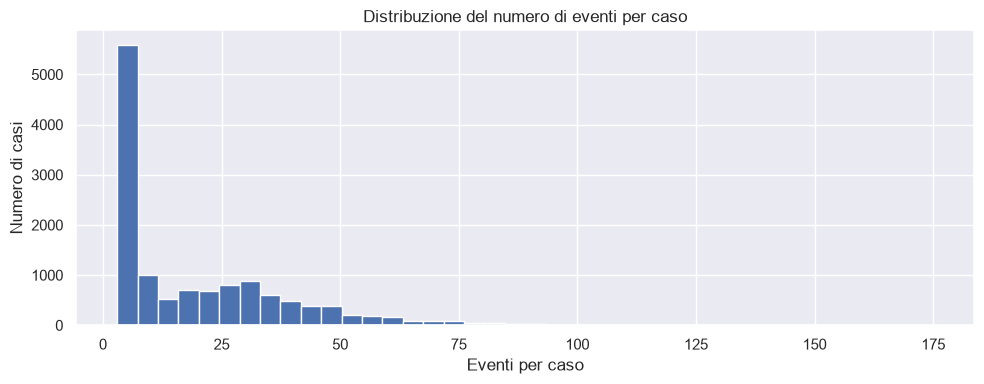

In [99]:
trace_lengths = log.groupby(CASE_COL).size().rename("eventi_per_caso")

ax = trace_lengths.hist(bins=40, figsize=(10, 4))
ax.set_title("Distribuzione del numero di eventi per caso")
ax.set_xlabel("Eventi per caso")
ax.set_ylabel("Numero di casi")
plt.tight_layout()
plt.show()

## 7. Lifecycle: capire SCHEDULE, START e COMPLETE

Questa è la caratteristica più importante di BPIC12 da comprendere prima del discovery.

- `SCHEDULE`: il work item viene messo in coda / pianificato;
- `START`: il lavoro viene avviato;
- `COMPLETE`: il lavoro termina.

Le etichette sono valori dell'attributo lifecycle, non necessariamente attività di business diverse. Per il process discovery tradizionale spesso si mantiene un solo evento di completamento per ogni attività. Il log grezzo, invece, serve per studiare il ciclo di vita del lavoro e alcune durate.

,eventi
lifecycle_norm,
complete,164506
start,71376
schedule,26318


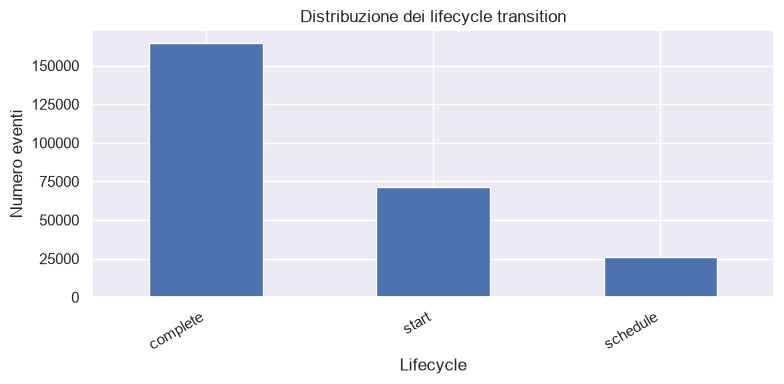

In [100]:
if LIFECYCLE_COL in log.columns:
    lifecycle_counts = log["lifecycle_norm"].value_counts(dropna=False)
    display(lifecycle_counts.rename("eventi").to_frame())

    ax = lifecycle_counts.plot(kind="bar", figsize=(8, 4))
    ax.set_title("Distribuzione dei lifecycle transition")
    ax.set_xlabel("Lifecycle")
    ax.set_ylabel("Numero eventi")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Attributo lifecycle non presente in questo file.")

In [101]:
# Quante attività distinte troviamo per ciascun prefisso A, O e W?
activity_prefixes = (
    log[ACTIVITY_COL]
    .str.extract(r"^([A-Z])_", expand=False)
    .fillna("OTHER")
)

activities_by_prefix = (
    pd.DataFrame({"prefix": activity_prefixes, "activity": log[ACTIVITY_COL]})
    .groupby("prefix")["activity"]
    .nunique()
    .sort_values(ascending=False)
)
display(activities_by_prefix.rename("attività_distinte").to_frame())

,attività_distinte
prefix,
A,10
O,7
W,7


### 7.1 Creare il log dei soli eventi completati
**Attenzione:** il filtro `COMPLETE` è una scelta di modellazione, non una pulizia universalmente obbligatoria. Escludendo `START` e `SCHEDULE` perdiamo informazioni utili su pianificazione e inizio del lavoro; per questo conserviamo `log` invariato e usiamo `log_complete` come vista derivata.

In [102]:
if LIFECYCLE_COL in log.columns:
    log_complete = log[log["lifecycle_norm"].eq("complete")].copy()
else:
    warnings.warn("Lifecycle assente: il log_complete coincide con il log importato.")
    log_complete = log.copy()

log_complete = log_complete.sort_values([CASE_COL, TIMESTAMP_COL]).reset_index(drop=True)

print("Log originale:", log.shape)
print("Log COMPLETE:", log_complete.shape)
print("Casi COMPLETE:", log_complete[CASE_COL].nunique())
print("Attività COMPLETE:", log_complete[ACTIVITY_COL].nunique())

Log originale: (262200, 8)
Log COMPLETE: (164506, 8)
Casi COMPLETE: 13087
Attività COMPLETE: 23


## 9. Esplorazione delle attività

### 9.1 Frequenza eventi per attività sul log grezzo

,eventi
concept:name,
W_Completeren aanvraag,54850
W_Nabellen offertes,52016
W_Nabellen incomplete dossiers,25190
W_Valideren aanvraag,20809
W_Afhandelen leads,16566
A_SUBMITTED,13087
A_PARTLYSUBMITTED,13087
A_DECLINED,7635
A_PREACCEPTED,7367


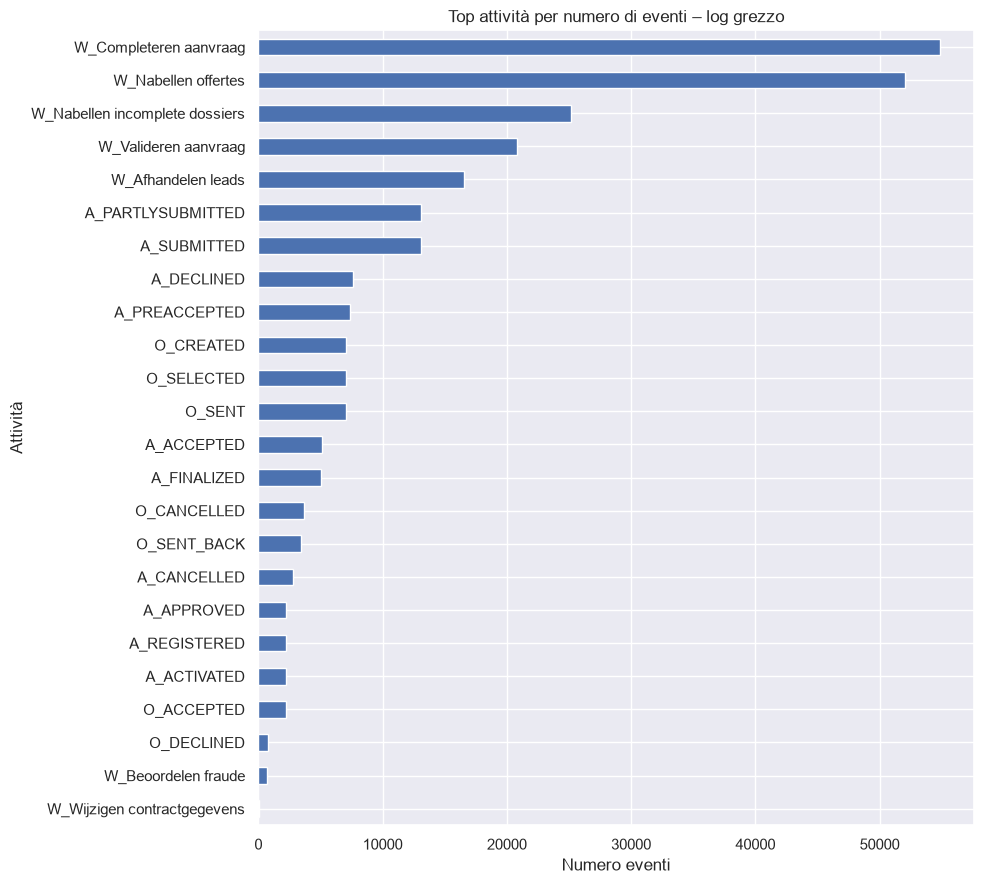

In [103]:
activity_freq_raw = log[ACTIVITY_COL].value_counts()
display(activity_freq_raw.rename("eventi").to_frame().head(40))

ax = activity_freq_raw.head(30).sort_values().plot(kind="barh", figsize=(10, 9))
ax.set_title("Top attività per numero di eventi – log grezzo")
ax.set_xlabel("Numero eventi")
ax.set_ylabel("Attività")
plt.tight_layout()
plt.show()

### 9.2 Frequenza sul log COMPLETE

,eventi_complete
concept:name,
W_Completeren aanvraag,23967
W_Nabellen offertes,22976
A_SUBMITTED,13087
A_PARTLYSUBMITTED,13087
W_Nabellen incomplete dossiers,11407
W_Valideren aanvraag,7895
A_DECLINED,7635
A_PREACCEPTED,7367
O_SELECTED,7030


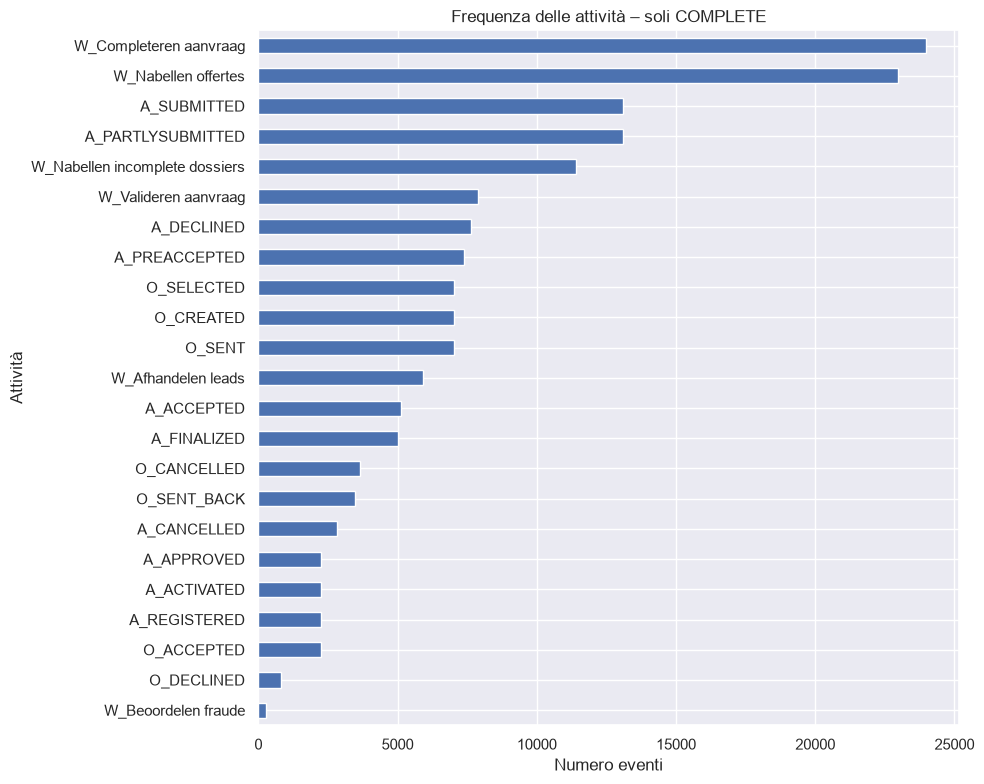

In [104]:
activity_freq_complete = log_complete[ACTIVITY_COL].value_counts()
display(activity_freq_complete.rename("eventi_complete").to_frame())

ax = activity_freq_complete.sort_values().plot(kind="barh", figsize=(10, 8))
ax.set_title("Frequenza delle attività – soli COMPLETE")
ax.set_xlabel("Numero eventi")
ax.set_ylabel("Attività")
plt.tight_layout()
plt.show()

### 9.3 Prefissi A, O e W

In [105]:
log_complete["activity_prefix"] = (
    log_complete[ACTIVITY_COL].str.extract(r"^([A-Z])_", expand=False).fillna("OTHER")
)

prefix_summary = log_complete.groupby("activity_prefix").agg(
    eventi=(ACTIVITY_COL, "size"),
    attività_distinte=(ACTIVITY_COL, "nunique"),
    casi_distinti=(CASE_COL, "nunique")
).sort_values("eventi", ascending=False)

display(prefix_summary)

,eventi,attività_distinte,casi_distinti
activity_prefix,,,
W,72413,6,9658
A,60849,10,13087
O,31244,7,5015


## 10. Risorse e attributi di caso

### 10.1 Risorse

,eventi
org:resource,
112,45687
NaN,18010
11169,7825
10138,7690
11181,7551
10861,7382
10609,7049
10913,6842
11189,6778


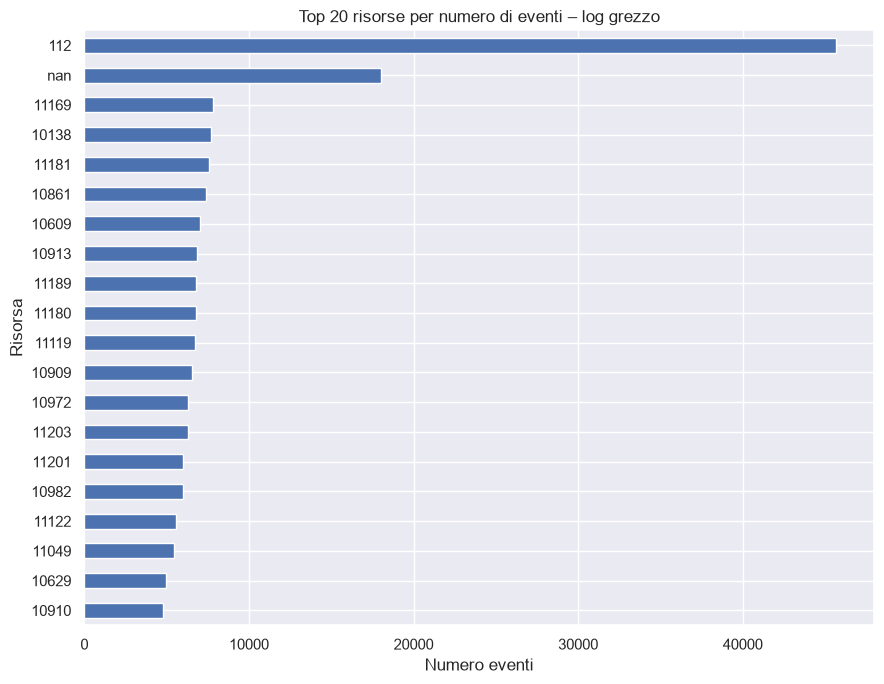

In [106]:
if RESOURCE_COL in log.columns:
    resource_freq = log[RESOURCE_COL].value_counts(dropna=False)
    display(resource_freq.head(30).rename("eventi").to_frame())

    ax = resource_freq.head(20).sort_values().plot(kind="barh", figsize=(9, 7))
    ax.set_title("Top 20 risorse per numero di eventi – log grezzo")
    ax.set_xlabel("Numero eventi")
    ax.set_ylabel("Risorsa")
    plt.tight_layout()
    plt.show()
else:
    print("org:resource non disponibile.")

### 10.2 Attributi di caso

In [107]:
case_attribute_cols = [
    c for c in log.columns
    if c.startswith("case:") and c != CASE_COL
]

print("Attributi di caso trovati:", case_attribute_cols)

Attributi di caso trovati: ['case:REG_DATE', 'case:AMOUNT_REQ']


## 11. Start activities ed end activities

In [108]:
start_activities = pm4py.get_start_activities(log_complete)
end_activities = pm4py.get_end_activities(log_complete)

print("Start activities:")
print(dict(sorted(start_activities.items(), key=lambda x: x[1], reverse=True)))
print("\nEnd activities:")
print(dict(sorted(end_activities.items(), key=lambda x: x[1], reverse=True)))

Start activities:
{'A_SUBMITTED': 13087}

End activities:
{'A_DECLINED': 3429, 'W_Valideren aanvraag': 2749, 'W_Afhandelen leads': 2234, 'W_Completeren aanvraag': 1939, 'W_Nabellen offertes': 1291, 'A_CANCELLED': 655, 'W_Nabellen incomplete dossiers': 453, 'O_CANCELLED': 279, 'W_Beoordelen fraude': 57, 'A_REGISTERED': 1}


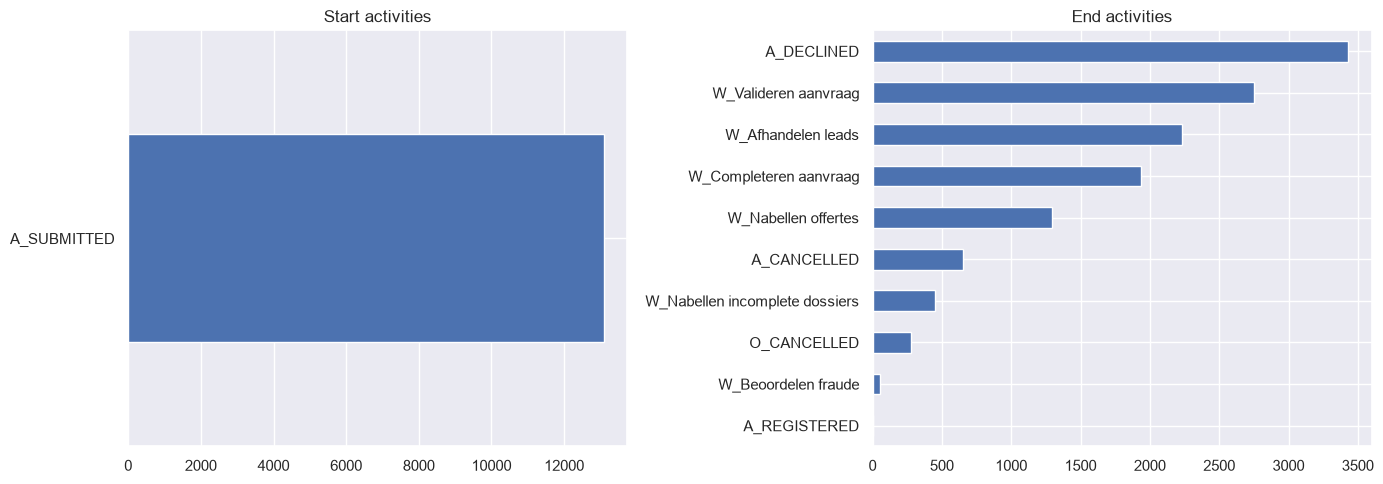

In [109]:
start_df = pd.Series(start_activities, name="frequenza").sort_values(ascending=False)
end_df = pd.Series(end_activities, name="frequenza").sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
start_df.head(15).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Start activities")
end_df.head(15).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("End activities")
plt.tight_layout()
plt.show()

## 12. Varianti

Una **variante** è una sequenza distinta di attività osservata in uno o più casi. Calcoliamo le varianti sul log COMPLETE: in questo modo `W_*` non viene contato più volte soltanto perché il log contiene le transizioni schedule/start/complete.

In [110]:
variants_by_case = (
    log_complete.sort_values([CASE_COL, TIMESTAMP_COL])
    .groupby(CASE_COL)[ACTIVITY_COL]
    .agg(tuple)
)

variant_counts = (
    variants_by_case.value_counts()
    .rename_axis("variante")
    .reset_index(name="frequenza")
)

print("Numero varianti:", len(variant_counts))
display(variant_counts.head(20))

Numero varianti: 4336


,variante,frequenza
0,"(A_SUBMITTED, A_PARTLYSUBMITTED, A_DECLINED)",3429
1,"(A_SUBMITTED, A_PARTLYSUBMITTED, A_DECLINED, W_Afhandelen leads)",1872
2,"(A_SUBMITTED, A_PARTLYSUBMITTED, W_Afhandelen leads, A_DECLINED, W_Afhandelen leads)",271
3,"(A_SUBMITTED, A_PARTLYSUBMITTED, A_PREACCEPTED, W_Afhandelen leads, A_DECLINED, W_Completeren aanvraag)",209
4,"(A_SUBMITTED, A_PARTLYSUBMITTED, A_PREACCEPTED, A_DECLINED, W_Completeren aanvraag)",160
5,"(A_SUBMITTED, A_PARTLYSUBMITTED, A_PREACCEPTED, A_CANCELLED, W_Completeren aanvraag)",134
6,"(A_SUBMITTED, A_PARTLYSUBMITTED, A_PREACCEPTED, W_Afhandelen leads, W_Completeren aanvraag, A_DECLINED, W_Completere...",126
7,"(A_SUBMITTED, A_PARTLYSUBMITTED, A_PREACCEPTED, W_Completeren aanvraag, A_DECLINED, W_Completeren aanvraag)",93
8,"(A_SUBMITTED, A_PARTLYSUBMITTED, A_PREACCEPTED, W_Completeren aanvraag, A_CANCELLED, W_Completeren aanvraag)",89
9,"(A_SUBMITTED, A_PARTLYSUBMITTED, A_PREACCEPTED, W_Afhandelen leads, W_Completeren aanvraag, W_Completeren aanvraag, ...",74


/var/folders/71/62mn_0fs1dx5w282pjw7pfc80000gn/T/ipykernel_27892/672898320.py:7: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


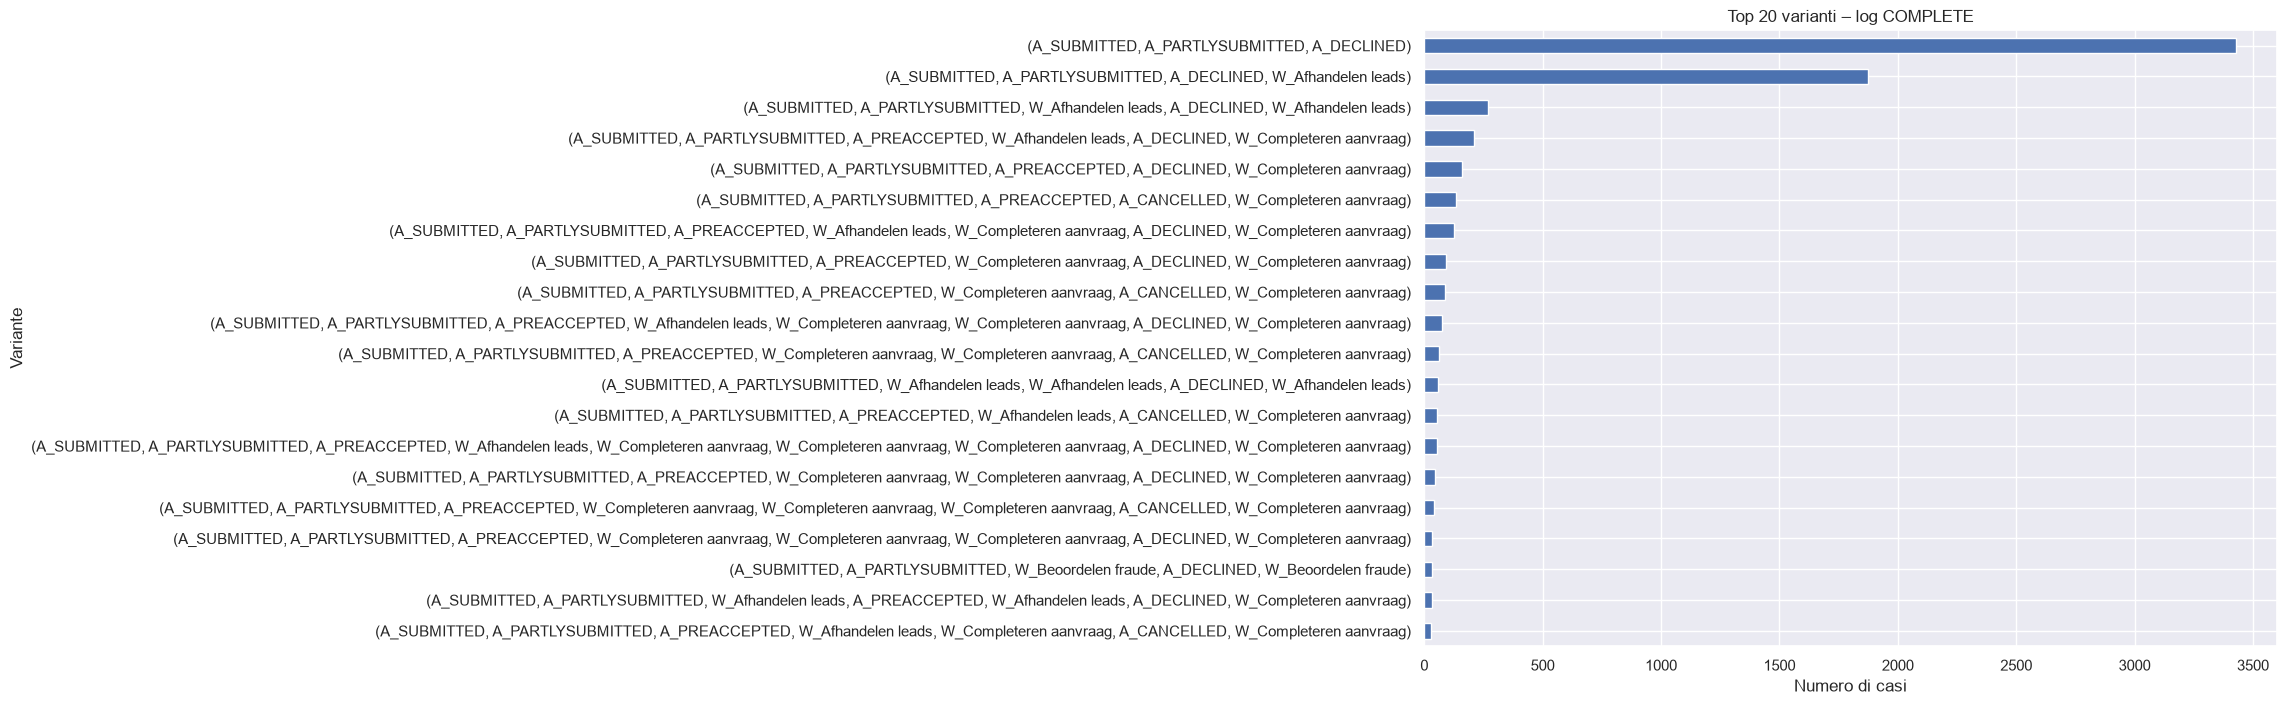

In [91]:
ax = variant_counts.head(20).sort_values("frequenza").plot(
    x="variante", y="frequenza", kind="barh", figsize=(11, 8), legend=False
)
ax.set_title("Top 20 varianti – log COMPLETE")
ax.set_xlabel("Numero di casi")
ax.set_ylabel("Variante")
plt.tight_layout()
plt.show()

**Interpretazione:** se la distribuzione è molto concentrata su poche varianti, il processo è più regolare; una coda lunga di varianti rare segnala eterogeneità, eccezioni, rumore oppure sottoprocessi differenti. Una variante rara non è automaticamente un errore.

## 13. Scomporre i sottoprocessi A, O e W

Il BPIC12 è un log composto da sottoprocessi intrecciati. Le tre famiglie non sono semplicemente tre alternative dello stesso flusso:

- **A (Application):** stati della domanda;
- **O (Offer):** stati dell'offerta, presenti in una parte dei casi;
- **W (Work):** work item svolti dagli operatori.

Prima di scoprire un modello unico, è utile capire quali casi contengono ciascuna famiglia.

In [112]:
log_complete = log_complete.copy()
log_complete["prefix"] = log_complete[ACTIVITY_COL].str.extract(r"^([A-Z])_", expand=False)

case_prefix_presence = pd.crosstab(
    log_complete[CASE_COL],
    log_complete["prefix"].fillna("OTHER")
).gt(0)

for prefix in ["A", "O", "W"]:
    if prefix not in case_prefix_presence.columns:
        case_prefix_presence[prefix] = False

case_prefix_presence["profile"] = case_prefix_presence.apply(
    lambda row: "+".join([p for p in ["A", "W", "O"] if row[p]]) or "NONE",
    axis=1
)

profile_counts = case_prefix_presence["profile"].value_counts()
display(profile_counts.rename("numero_casi").to_frame())

,numero_casi
profile,
A+W+O,5015
A+W,4643
A,3429


### 14 Costruire i sotto-log per prefisso

In [114]:
log_A = log_complete[log_complete[ACTIVITY_COL].str.startswith("A_", na=False)].copy()
log_O = log_complete[log_complete[ACTIVITY_COL].str.startswith("O_", na=False)].copy()
log_W = log_complete[log_complete[ACTIVITY_COL].str.startswith("W_", na=False)].copy()
log_AW_events = log_complete[log_complete[ACTIVITY_COL].str.startswith(("A_", "W_"), na=False)].copy()


def describe_sublog(name, sublog):
    print(
        f"{name:12s} | eventi={len(sublog):>8,} | "
        f"casi={sublog[CASE_COL].nunique():>6,} | "
        f"attività={sublog[ACTIVITY_COL].nunique():>3}"
    )

for name, sublog in [
    ("A only", log_A),
    ("O only", log_O),
    ("W only", log_W),
    ("A+W events", log_AW_events),
    ("A+O+W", log_complete)
]:
    describe_sublog(name, sublog)

A only       | eventi=  60,849 | casi=13,087 | attività= 10
O only       | eventi=  31,244 | casi= 5,015 | attività=  7
W only       | eventi=  72,413 | casi= 9,658 | attività=  6
A+W events   | eventi= 133,262 | casi=13,087 | attività= 16
A+O+W        | eventi= 164,506 | casi=13,087 | attività= 23


### 14.1 Confrontare le attività dei sottoprocessi

In [115]:
subprocess_activity_table = pd.concat({
    "A": log_A[ACTIVITY_COL].value_counts(),
    "O": log_O[ACTIVITY_COL].value_counts(),
    "W": log_W[ACTIVITY_COL].value_counts()
}, axis=1).fillna(0).astype(int)

display(subprocess_activity_table)

,A,O,W
concept:name,,,
A_SUBMITTED,13087,0,0
A_PARTLYSUBMITTED,13087,0,0
A_DECLINED,7635,0,0
A_PREACCEPTED,7367,0,0
A_ACCEPTED,5113,0,0
A_FINALIZED,5015,0,0
A_CANCELLED,2807,0,0
A_REGISTERED,2246,0,0
A_APPROVED,2246,0,0


## 16. Filtri per analisi mirate

### 16.1 Filtrare per famiglia di attività

In [120]:
# Esempio: eventi di work item già completati.
log_W_complete = log_complete[
    log_complete[ACTIVITY_COL].str.startswith("W_", na=False)
].copy()

describe_sublog("W complete", log_W_complete)

W complete   | eventi=  72,413 | casi= 9,658 | attività=  6


In [124]:
# Prendiamo le prime K sequenze e conserviamo i casi che le eseguono.
TOP_K_VARIANTS = 20
top_variants = set(variant_counts.head(TOP_K_VARIANTS)["variante"])
top_variant_case_ids = variants_by_case[variants_by_case.isin(top_variants)].index
log_top_variants = log_complete[log_complete[CASE_COL].isin(top_variant_case_ids)].copy()

describe_sublog(f"top {TOP_K_VARIANTS} varianti", log_top_variants)

top 20 varianti | eventi=  27,504 | casi= 6,897 | attività=  8


## 17. Directly-Follows Graph (DFG)

Il DFG è un grafo orientato:

- i nodi rappresentano attività;
- un arco `A → B` indica che B segue direttamente A in almeno una traccia;
- il peso è il numero di occorrenze della successione.

Per la prima analisi useremo il log `log_complete`, per evitare che `START` e `COMPLETE` della stessa work activity vengano trattati come due esecuzioni distinte dell'attività.

In [128]:
log_for_discovery = log_complete.copy()

dfg, dfg_starts, dfg_ends = pm4py.discover_dfg(log_for_discovery)

print("Numero archi:", len(dfg))
print("Start:", dfg_starts)
print("End:", dfg_ends)

Numero archi: 138
Start: {'A_SUBMITTED': 13087}
End: {'W_Valideren aanvraag': 2749, 'A_DECLINED': 3429, 'W_Completeren aanvraag': 1939, 'A_CANCELLED': 655, 'W_Nabellen incomplete dossiers': 453, 'W_Afhandelen leads': 2234, 'W_Nabellen offertes': 1291, 'W_Beoordelen fraude': 57, 'O_CANCELLED': 279, 'A_REGISTERED': 1}


In [129]:
dfg_table = pd.DataFrame([
    {"source": source, "target": target, "frequency": frequency}
    for (source, target), frequency in dfg.items()
]).sort_values("frequency", ascending=False).reset_index(drop=True)

display(dfg_table.head(40))

,source,target,frequency
0,W_Nabellen offertes,W_Nabellen offertes,13521
1,A_SUBMITTED,A_PARTLYSUBMITTED,13087
2,W_Completeren aanvraag,W_Completeren aanvraag,12619
3,W_Nabellen incomplete dossiers,W_Nabellen incomplete dossiers,8620
4,O_CREATED,O_SENT,7030
5,A_PARTLYSUBMITTED,A_PREACCEPTED,6959
6,A_PARTLYSUBMITTED,A_DECLINED,5301
7,O_SENT,W_Completeren aanvraag,5015
8,W_Completeren aanvraag,W_Nabellen offertes,3554
9,O_SENT_BACK,W_Nabellen offertes,3254


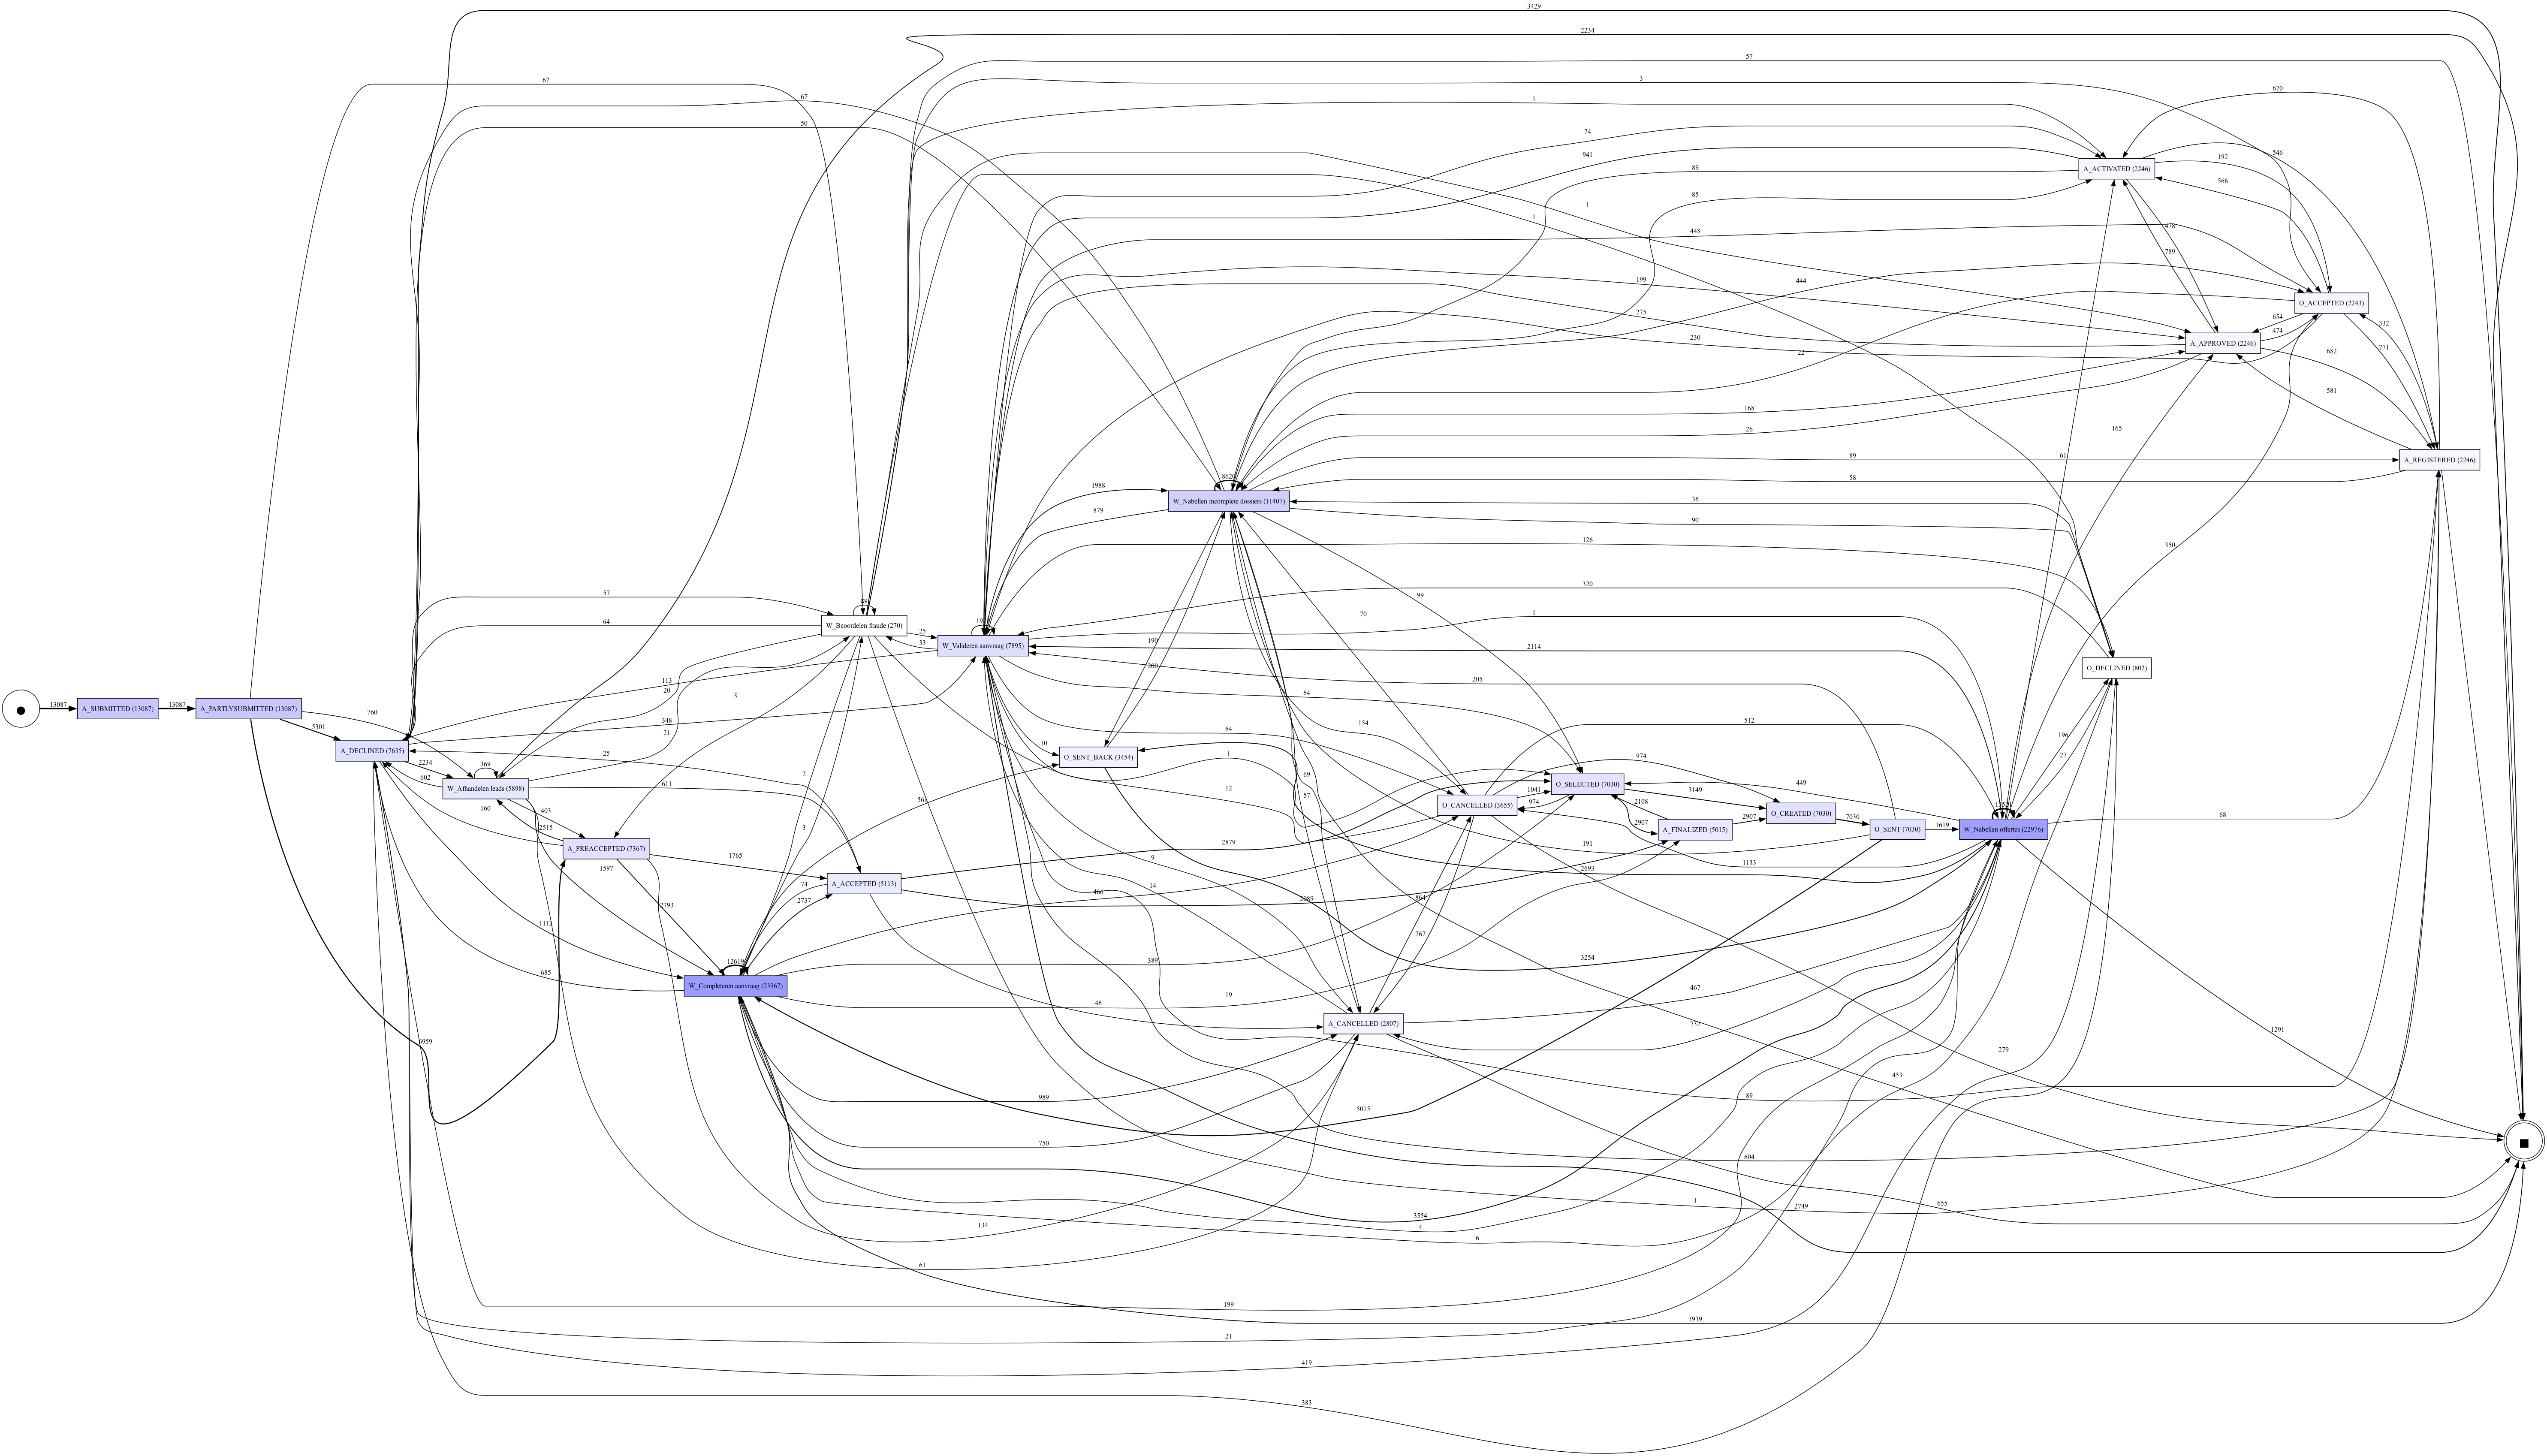

In [130]:
# Grafico DFG: può richiedere Graphviz.
pm4py.view_dfg(
    dfg,
    dfg_starts,
    dfg_ends,
    format="png"
)

### 17.1 Salvare il DFG e la tabella degli archi

In [131]:
OUTPUT_DIR = Path("output_bpic12")
OUTPUT_DIR.mkdir(exist_ok=True)

dfg_table.to_csv(OUTPUT_DIR / "bpic12_dfg_edges.csv", index=False)
pm4py.save_vis_dfg(
    dfg,
    dfg_starts,
    dfg_ends,
    str(OUTPUT_DIR / "bpic12_dfg.svg")
)
print("Salvati gli artefatti in:", OUTPUT_DIR.resolve())

Salvati gli artefatti in: /Users/vincenzo/Documents/lezioni/DMII/process_mining/output_bpic12


**Limite del DFG:** un arco ciclico non distingue da solo un loop operativo, un ritorno di stato o un parallelismo. Il DFG è descrittivo e basato sulle successioni osservate; non è un modello completo della semantica di controllo.

## 18. Performance DFG

Il Performance DFG associa alle successioni dirette una misura temporale invece della sola frequenza. La misura si basa sulle differenze tra timestamp di eventi consecutivi della traccia.

In [ ]:
performance_dfg, perf_starts, perf_ends = pm4py.discover_performance_dfg(log_for_discovery)

print("Relazioni temporali:", len(performance_dfg))
print(list(performance_dfg.items())[:10])

Relazioni temporali: 22
[(('A_CANCELLED', 'W_Completeren aanvraag'), {'mean': np.float64(1.8559756690997569), 'median': np.float64(1.664), 'max': np.float64(6.575), 'min': np.float64(0.0), 'sum': np.float64(762.806), 'stdev': np.float64(0.6093597154564759)}), (('A_DECLINED', 'W_Afhandelen leads'), {'mean': np.float64(3.7576378918673328), 'median': np.float64(3.412), 'max': np.float64(111.864), 'min': np.float64(2.262), 'sum': np.float64(8270.561), 'stdev': np.float64(4.067042709970869)}), (('A_DECLINED', 'W_Beoordelen fraude'), {'mean': np.float64(2.63825), 'median': np.float64(2.3665000000000003), 'max': np.float64(5.34), 'min': np.float64(1.955), 'sum': np.float64(84.424), 'stdev': np.float64(0.6752687398123373)}), (('A_DECLINED', 'W_Completeren aanvraag'), {'mean': np.float64(3.837498786407767), 'median': np.float64(3.5060000000000002), 'max': np.float64(45.109), 'min': np.float64(2.211), 'sum': np.float64(3162.099), 'stdev': np.float64(2.6196331224489855)}), (('A_PARTLYSUBMITTED', 

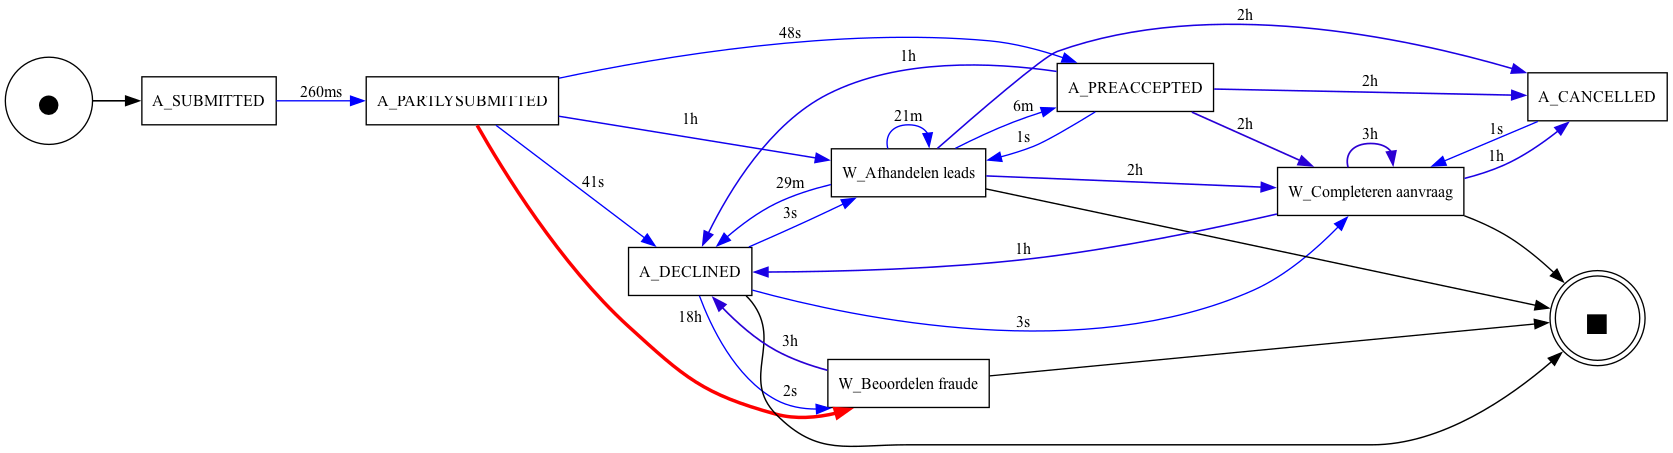

In [133]:
# La visualizzazione PM4Py supporta aggregazioni come mean, median, min e max.
pm4py.view_performance_dfg(
    performance_dfg,
    perf_starts,
    perf_ends,
    format="png",
    aggregation_measure="median"
)

La mediana è spesso più robusta della media in presenza di tempi di attesa molto asimmetrici. Ricorda che si tratta di tempo tra eventi consecutivi osservati, non necessariamente di tempo effettivo di lavorazione.